# Phase 04 · Notebook 3: the connectome without plasticity

## What the wiring of Johnston's organ achieves with fixed weights

This network uses the real wiring of the connectome with **static weights**, so it learns nothing. It is the condition that isolates the contribution of the **wiring** on its own, and the reference against which the next notebook measures what plasticity adds.

It is also, in essence, the kind of model used in whole-brain simulations constrained by a connectome: a network whose weights come from the number of synaptic contacts and never change. Shiu et al. (2024) built such a model of the whole fly brain, with LIF neurons simulated in Brian2, on an earlier FlyWire release (v630).

### Background for readers new to the project

This project asks whether a spiking network wired like an auditory circuit of the fruit fly learns a sound task better than networks of the same size with artificial wiring. The circuit is that of **Johnston's organ** (JO), the fly's ear, taken from the FlyWire **connectome**, the map of all the neurons of the fly brain and of the connections between them (Dorkenwald et al., 2024).

The sound is the **courtship song**, a train of brief song pulses that a male produces by vibrating one wing. The time between consecutive pulses is the **inter-pulse interval** (IPI), one of the cues a female uses to recognize males of her species (Bennet-Clark & Ewing, 1969). The task is to tell apart five songs whose IPIs go from 25 to 65 ms. **Spike encoding** turns each song into spikes for the input layer of the network. A **gammatone filterbank** first splits the sound into 32 frequency bands (Patterson et al., 1992), and an **inner-hair-cell model**, named after the cells that do this in the mammalian ear, turns each band into a firing rate that drives random spikes. The [audio-encoding notebook](01-audio-encoding.ipynb) builds and checks that chain.

In a **spiking neural network** (SNN) neurons communicate with brief electrical events called **spikes**. Ours are **leaky integrate-and-fire** (LIF) neurons with **three synaptic channels**, one excitatory, one inhibitory and one modulatory. Each neuron adds up the current of its channels, leaks it slowly and fires when its voltage crosses a threshold. The networks learn with **spike-timing-dependent plasticity** (STDP), a local rule that strengthens a connection when the sending neuron fires just before the receiving one and weakens it when it fires just after (Song et al., 2000). **Winner-take-all** (WTA) inhibition, a pool of inhibitory neurons, holds the network back when many neurons fire at once, so that a few of them specialize.

The **linear readout** is a logistic regression that names the song from the spike count of each neuron. With five songs the **chance level** is 0.200. The **input-only ceiling**, the accuracy of the same readout applied to the input layer alone, is 0.223. What a network achieves above that ceiling is what the network computes.

The design has six experimental **arms**: three wirings, each run with static weights and with STDP + WTA. Each arm runs with several **seeds**, the numbers that fix the random generators so that a run can be repeated exactly. A **paired comparison** sets two arms side by side seed by seed, so that only the factor of interest changes. The **effect size**, Cohen's d, measures a difference between arms in units of their standard deviation (Cohen, 1988/2013). The **spikes per correct classification**, all the spikes the network fires during the test divided by the number of correct answers, measure what each answer costs.

This notebook reports the static connectome arm. The controls are in [notebook 2](02-control-networks.ipynb), and the six arms are compared together in [notebook 4](04-connectome-stdp.ipynb).

## 0. Environment and results

This notebook runs no simulation. The cell loads the subgraph, the operating point calibrated in phase 03 and the stored results of the experiments (`outputs/results.json` and `outputs/extra_seeds.json`). `summary` returns the mean and standard deviation of one metric for one arm, and `arm_table` lists the metrics of every seed.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from snnlib import audio as A, evaluation as E, graph, network as NET, FIGURES
from snnlib.evaluation import IPIS, PAIRS, WINDOWS_MS

FIGURES.mkdir(exist_ok=True)
OUT_DIR = Path('outputs')
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':150,'savefig.bbox':'tight',
                     'axes.titleweight':'bold','font.size':10})
BLUE, RED, GREEN, PURPLE, GRAY = '#2E86AB','#C73E1D','#3CAEA3','#7B68A6','#8A948F'

C = graph.load()
OP = json.loads((Path('..')/'03-data-preparation'/'outputs'/'operating_point.json').read_text())
RES = E.load_results()   # joins results.json and extra_seeds.json
CHANCE = 1/len(IPIS)

def summary(arm, col='accuracy'):
    d = RES[RES.arm==arm][col]
    return d.mean(), d.std()

def arm_table(arm):
    d = RES[RES.arm==arm]
    rows = []
    for _, r in d.iterrows():
        rows.append(dict(seed=int(r.seed), accuracy=r.accuracy,
                         rate_hz=r.mean_rate_hz, spikes_per_correct=r.spikes_per_correct,
                         selectivity=r.selectivity, coverage=r.coverage_pct))
    t = pd.DataFrame(rows).set_index('seed')
    return pd.concat([t, t.agg(['mean','std'])]).round(3)

## 1. The network

The network has 1,239 neurons and 20,059 **connections**, directed pairs of neurons. Together they add up to 338,013 synaptic contacts, the physical sites where one neuron passes a signal to another. The weight of each connection is the number of contacts that form it, and none has fewer than five, because of the threshold applied in phase 02.

The input layer consists of 123 neurons of Johnston's organ, those that have at least one outgoing connection and can therefore pass the stimulus on. The other 146 JO neurons of the graph remain part of the network, since they receive feedback from central neurons, but no stimulus is injected into them. Injecting it there would lead to a dead end. Every neuron that receives no stimulus belongs to the **readout population**, the neurons the readout listens to.

In [2]:
print(f'Neurons: {C.N}   connections: {len(C.pre):,}   synaptic contacts: {int(C.raw_weight.sum()):,}')
print('Polarities:', {k:int(v.sum()) for k,v in C.mask.items()})
print(f'JO neurons in the graph: {int(C.is_jo.sum())}')
print(f'Input layer (JO neurons with an outgoing connection): {C.N_input}')
print(f'Readout population (every neuron that receives no stimulus): {int((~C.is_input).sum())}')
cfg = OP['arms']['connectome_static']
print(f'\nCalibrated input gain: w_input = {cfg["w_input"]:.3f} nA')
print(f'Resulting mean rate: {cfg["rate"]:.2f} ± {cfg["rate_sd"]:.2f} Hz')

Neurons: 1239   connections: 20,059   synaptic contacts: 338,013
Polarities: {'Excitatory': 8512, 'Inhibitory': 11437, 'Modulatory': 110}
JO neurons in the graph: 269
Input layer (JO neurons with an outgoing connection): 123
Readout population (every neuron that receives no stimulus): 1116

Calibrated input gain: w_input = 10.075 nA
Resulting mean rate: 10.41 ± 0.46 Hz


Of the 20,059 connections, 8,512 are excitatory, 11,437 inhibitory and 110 modulatory. The readout listens to 1,116 neurons. With the input gain calibrated in phase 03 (10.075 nA), the static connectome fires at 10.41 ± 0.46 Hz on average, on the common operating point.

## 2. Classification performance

This section measures the same thing in two different ways. They are worth telling apart before looking at the numbers, because **each has its own chance level**.

- **The full test, with five options.** A song plays and the network has to say which of the five it was (25, 35, 45, 55 or 65 ms). Answering blindly would be right one time in five, so chance is **0.200**.
- **The five duels, with two options.** The same idea, but choosing between only two songs, such as "was it 45 or 55?". A blind answer is right half the time, so here chance is **0.500**.

The duels are not new simulations. They come from the same set of responses, by restricting the readout to two classes. They are also an easier question than the full test, so **their numbers come out higher and are not directly comparable** with the five-class one. Each is read against its own chance line. So 0.566 against a chance of 0.200 on the full test and 0.750 against a chance of 0.500 on the hardest duel are not two scores on one scale. They answer different questions and are not compared.

In [3]:
m,s = summary('connectome_static')
print(f'Accuracy (5 classes): {m:.3f} ± {s:.3f}   (chance = {CHANCE:.3f})')
print()
arm_table('connectome_static')

Accuracy (5 classes): 0.566 ± 0.082   (chance = 0.200)



,accuracy,rate_hz,spikes_per_correct,selectivity,coverage
0,0.550,10.432,5874.873,0.913,19.139
1,0.540,10.408,5969.963,0.911,19.266
2,0.640,10.475,5069.969,0.913,19.193
3,0.450,10.344,7119.778,0.913,19.168
4,0.650,10.254,4886.631,0.913,19.009
mean,0.566,10.383,5784.243,0.913,19.155
std,0.082,0.086,886.320,0.001,0.094


With fixed weights the connectome reaches 0.566 ± 0.082 on the five-class task, well above the chance level of 0.200 and the input-only ceiling of 0.223. The table lists the five seeds. The firing rate stays on the operating point (10.383 Hz on average), and the five seeds barely differ in rate, selectivity or coverage. The spread in accuracy (± 0.082) is much larger than the spread in activity.

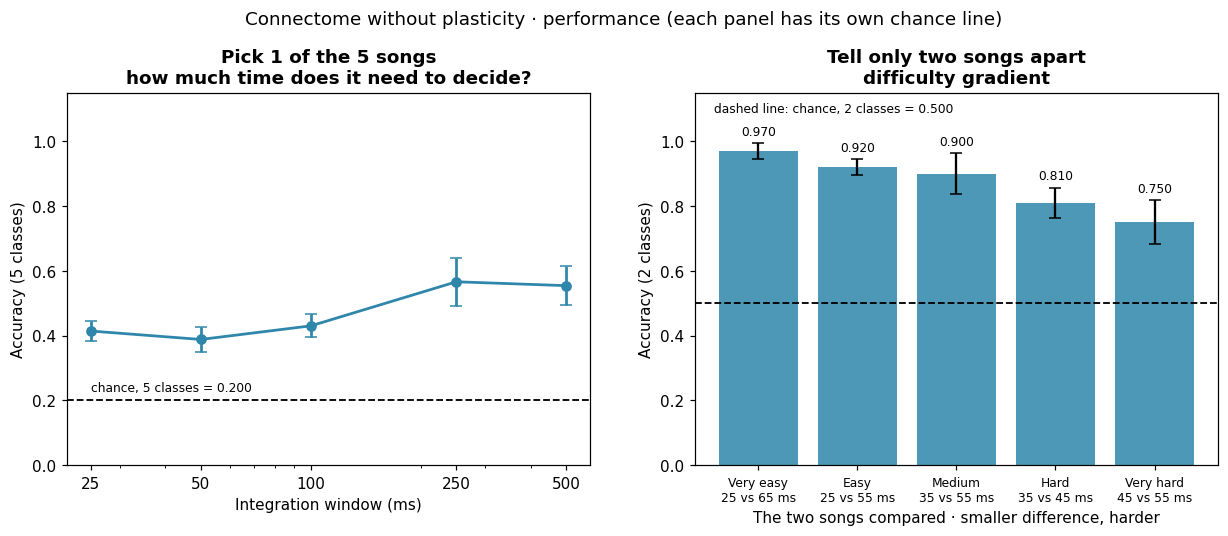

In [4]:
d = RES[RES.arm=='connectome_static']
curves = np.array([list(r.values()) for r in d.accuracy_vs_window])
LABEL_BOX = dict(fc='white', ec='none', alpha=.85, pad=1.5)
fig, ax = plt.subplots(1,2, figsize=(13.5,4.4))

# Left: the full test. Pick 1 of the 5 songs, chance = 0.200.
ax[0].errorbar(WINDOWS_MS, curves.mean(axis=0), yerr=curves.std(axis=0),
               marker='o', color=BLUE, capsize=4, lw=1.8)
ax[0].axhline(CHANCE, color='k', ls='--', lw=1.2)
ax[0].text(WINDOWS_MS[0], CHANCE+.02, f'chance, 5 classes = {CHANCE:.3f}', fontsize=8,
           va='bottom', ha='left', bbox=LABEL_BOX)
ax[0].set_xscale('log'); ax[0].set_xticks(WINDOWS_MS); ax[0].set_xticklabels(WINDOWS_MS)
ax[0].set_xlabel('Integration window (ms)')
ax[0].set_ylabel('Accuracy (5 classes)'); ax[0].set_ylim(0,1.15)
ax[0].set_title('Pick 1 of the 5 songs\nhow much time does it need to decide?')

# Right: the five duels. Only two songs each time, so chance = 0.500.
names = [p[0] for p in PAIRS]
labels = [f'{n}\n{a} vs {b} ms' for n,a,b in PAIRS]
vals = [np.array([p[n] for p in d.pair_accuracy]) for n in names]
ax[1].bar(range(len(names)), [v.mean() for v in vals],
          yerr=[v.std() for v in vals], color=BLUE, alpha=.85, capsize=4)
for i,v in enumerate(vals):
    ax[1].text(i, v.mean()+v.std()+.025, f'{v.mean():.3f}', ha='center', fontsize=8)
ax[1].axhline(.5, color='k', ls='--', lw=1.2)
ax[1].text(-.45, 1.10, 'dashed line: chance, 2 classes = 0.500', fontsize=8, va='center', ha='left', bbox=LABEL_BOX)
ax[1].set_xticks(range(len(names))); ax[1].set_xticklabels(labels, fontsize=8)
ax[1].set_xlabel('The two songs compared · smaller difference, harder')
ax[1].set_ylabel('Accuracy (2 classes)'); ax[1].set_ylim(0,1.15)
ax[1].set_title('Tell only two songs apart\ndifficulty gradient')
fig.suptitle('Connectome without plasticity · performance (each panel has its own chance line)', y=1.05)
fig.savefig(FIGURES/'04-connectome-static-performance.png'); plt.show()

Left panel: five-class accuracy against the integration window, the length of the response (in ms) that the readout counts. Accuracy grows from 0.414 at 25 ms to 0.566 at 250 ms and does not improve at 500 ms (0.554). Right panel: the five two-class duels, from 0.970 on the easiest pair to 0.750 on the hardest. Each panel carries its own chance line, so the bars on the right must not be read against the 0.200 of the left panel.

## 3. The channel-to-neuron mapping

The 123 input neurons have a known cell subtype (phase 02), **87 JO-B and 36 JO-A**. JO-B prefers low-frequency vibration, below about 100 Hz, and JO-A carries the high-frequency responses (Kamikouchi et al., 2009; Matsuo et al., 2014). The default mapping uses this as a coarse tonotopic anchor, with JO-B on the low channels and JO-A on the high ones. We compare four mappings, the anchored one, its inverse, the earlier ordering by `root_id` and a random assignment, to check that the result does not depend on a lucky assignment.

One expectation is worth stating in advance. **In this task all the songs share the carrier**, so the frequency axis carries no information about the class. Tonotopy, the orderly mapping of frequency onto neurons, should not help here. Every mapping gives each channel the same number of input neurons, so what the mapping decides in practice is which neurons receive the song and how their activity spreads through the network.

The comparison between the anchored and the random mapping is a paired t-test, run seed by seed on the five seeds the two arms share.

  anchored to JO subtypes        0.566 ± 0.082
  inverted anchoring             0.758 ± 0.044
  root_id order                  0.676 ± 0.044
  random assignment              0.736 ± 0.045

Anatomical anchoring against random assignment: -0.170  (p=0.0327, paired by seed)

Tonotopic anchoring does NOT help in this task, and that was expected: the five
songs share the carrier, so there is no frequency axis to exploit.
Every mapping drives the same number of input neurons. What changes is which
ones, and so which partners downstream receive the song. The main results use
the anchored mapping, the least favorable one for the static connectome. The
control networks ran only with this mapping.


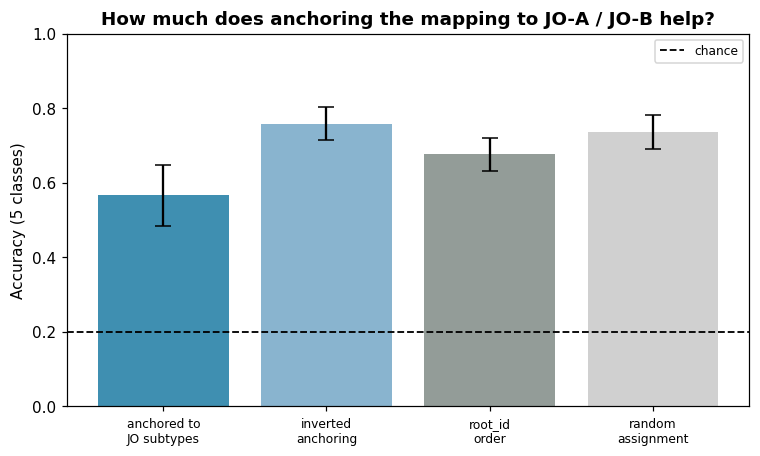

In [5]:
MAPPINGS = ['subtype','subtype_inverted','root_id','random']
LABELS = {'subtype':'anchored to\nJO subtypes','subtype_inverted':'inverted\nanchoring',
          'root_id':'root_id\norder','random':'random\nassignment'}
m_ = {k: RES[RES.arm==f'mapping_{k}_static'].accuracy for k in MAPPINGS}
for k in MAPPINGS:
    print(f'  {LABELS[k][:24].replace(chr(10)," "):30s} {m_[k].mean():.3f} ± {m_[k].std():.3f}')
from scipy import stats
a = RES[RES.arm=='mapping_subtype_static'].sort_values('seed').accuracy.values
b = RES[RES.arm=='mapping_random_static'].sort_values('seed').accuracy.values
print(f"\nAnatomical anchoring against random assignment: "
      f"{m_['subtype'].mean()-m_['random'].mean():+.3f}  "
      f"(p={stats.ttest_rel(a,b).pvalue:.4f}, paired by seed)")
print()
print('Tonotopic anchoring does NOT help in this task, and that was expected: the five')
print('songs share the carrier, so there is no frequency axis to exploit.')
print('Every mapping drives the same number of input neurons. What changes is which')
print('ones, and so which partners downstream receive the song. The main results use')
print('the anchored mapping, the least favorable one for the static connectome. The')
print('control networks ran only with this mapping.')

fig, ax = plt.subplots(figsize=(8,4.4))
cols_=[BLUE,'#7FAECB',GRAY,'#CCCCCC']
for i,k in enumerate(MAPPINGS):
    ax.bar(i, m_[k].mean(), yerr=m_[k].std(), color=cols_[i], capsize=5, alpha=.92)
ax.axhline(CHANCE, color='k', ls='--', lw=1.2, label='chance')
ax.set_xticks(range(4)); ax.set_xticklabels([LABELS[k] for k in MAPPINGS], fontsize=8)
ax.set_ylabel('Accuracy (5 classes)'); ax.set_ylim(0,1); ax.legend(fontsize=8)
ax.set_title('How much does anchoring the mapping to JO-A / JO-B help?')
fig.savefig(FIGURES/'04-channel-mapping-control.png'); plt.show()

In the static network the anchored mapping is the least favorable of the four (0.566 ± 0.082). The inverted one reaches 0.758 ± 0.044, the `root_id` order 0.676 ± 0.044 and the random assignment 0.736 ± 0.045. The anchored mapping falls 0.170 below the random one, and the paired test gives p = 0.0327. With plasticity the gap almost closes (Section 6 of [notebook 4](04-connectome-stdp.ipynb)). Because the main results use the anchored mapping, the connectome enters the comparison from its weakest starting point. Only the connectome was run with the four mappings; the control networks used the anchored one.

## 4. Spike cost

For neuromorphic computing, accuracy alone is not the criterion. The cost at which each correct answer comes matters too. On event-driven chips such as Loihi, energy is spent only when spikes occur (Schuman et al., 2022), and each synaptic spike operation costs at least 23.6 pJ (Davies et al., 2018). **Spikes per correct classification** are therefore a direct proxy for the activity a network needs. They are not an energy measurement, and the comparison with conventional networks in the [results of this phase](results.md) shows where that proxy stops.

The cell also reports two measures of how the response is distributed. **Selectivity** is the normalized Treves–Rolls sparseness of the response across neurons (Treves & Rolls, 1991; Vinje & Gallant, 2000). It goes from 0 when all neurons respond equally to 1 when a single neuron responds. **Coverage** is the percentage of the readout population that fires at least once.

In [6]:
print(f'Spikes per correct classification: {d.spikes_per_correct.mean():,.0f} '
      f'± {d.spikes_per_correct.std():,.0f}')
print(f'Selectivity (Treves-Rolls sparseness): {d.selectivity.mean():.3f}')
print(f'Coverage of the readout population: {d.coverage_pct.mean():.1f} %')
print()
print('High selectivity with low coverage means that the response is concentrated in')
print('a few neurons. Selectivity alone does not show that those neurons specialize.')
print('The comparison of these metrics across topologies is in the next notebook.')

Spikes per correct classification: 5,784 ± 886
Selectivity (Treves-Rolls sparseness): 0.913
Coverage of the readout population: 19.2 %

High selectivity with low coverage means that the response is concentrated in
a few neurons. Selectivity alone does not show that those neurons specialize.
The comparison of these metrics across topologies is in the next notebook.


Each correct answer of the static connectome costs 5,784 ± 886 spikes. Its selectivity is high (0.913) and about one readout neuron in five fires at least once (19.2 %). A few neurons carry most of the response to each song, at a moderate firing rate. [Notebook 4](04-connectome-stdp.ipynb) compares these numbers across the six arms.

## References

- Bennet-Clark, H. C., & Ewing, A. W. (1969). Pulse interval as a critical parameter in the courtship song of *Drosophila melanogaster*. *Animal Behaviour, 17*(4), 755–759. https://doi.org/10.1016/S0003-3472(69)80023-0
- Cohen, J. (2013). *Statistical power analysis for the behavioral sciences* (2nd ed.). Routledge. https://doi.org/10.4324/9780203771587 (Original work published 1988)
- Davies, M., Srinivasa, N., Lin, T.-H., Chinya, G., Cao, Y., Choday, S. H., Dimou, G., Joshi, P., Imam, N., Jain, S., Liao, Y., Lin, C.-K., Lines, A., Liu, R., Mathaikutty, D., McCoy, S., Paul, A., Tse, J., Venkataramanan, G., . . . Wang, H. (2018). Loihi: A neuromorphic manycore processor with on-chip learning. *IEEE Micro, 38*(1), 82–99. https://doi.org/10.1109/MM.2018.112130359
- Dorkenwald, S., Matsliah, A., Sterling, A. R., Schlegel, P., Yu, S.-c., McKellar, C. E., Lin, A., Costa, M., Eichler, K., Yin, Y., Silversmith, W., Schneider-Mizell, C., Jordan, C. S., Brittain, D., Halageri, A., Kuehner, K., Ogedengbe, O., Morey, R., Gager, J., . . . The FlyWire Consortium. (2024). Neuronal wiring diagram of an adult brain. *Nature, 634*(8032), 124–138. https://doi.org/10.1038/s41586-024-07558-y
- Kamikouchi, A., Inagaki, H. K., Effertz, T., Hendrich, O., Fiala, A., Göpfert, M. C., & Ito, K. (2009). The neural basis of *Drosophila* gravity-sensing and hearing. *Nature, 458*(7235), 165–171. https://doi.org/10.1038/nature07810
- Matsuo, E., Yamada, D., Ishikawa, Y., Asai, T., Ishimoto, H., & Kamikouchi, A. (2014). Identification of novel vibration- and deflection-sensitive neuronal subgroups in Johnston’s organ of the fruit fly. *Frontiers in Physiology, 5*, Article 179. https://doi.org/10.3389/fphys.2014.00179
- Patterson, R. D., Robinson, K., Holdsworth, J., McKeown, D., Zhang, C., & Allerhand, M. (1992). Complex sounds and auditory images. In Y. Cazals, L. Demany, & K. Horner (Eds.), *Auditory physiology and perception* (pp. 429–446). Pergamon. https://doi.org/10.1016/B978-0-08-041847-6.50054-X
- Schuman, C. D., Kulkarni, S. R., Parsa, M., Mitchell, J. P., Date, P., & Kay, B. (2022). Opportunities for neuromorphic computing algorithms and applications. *Nature Computational Science, 2*(1), 10–19. https://doi.org/10.1038/s43588-021-00184-y
- Shiu, P. K., Sterne, G. R., Spiller, N., Franconville, R., Sandoval, A., Zhou, J., Simha, N., Kang, C. H., Yu, S., Kim, J. S., Dorkenwald, S., Matsliah, A., Schlegel, P., Yu, S.-c., McKellar, C. E., Sterling, A., Costa, M., Eichler, K., Bates, A. S., . . . Scott, K. (2024). A *Drosophila* computational brain model reveals sensorimotor processing. *Nature, 634*(8032), 210–219. https://doi.org/10.1038/s41586-024-07763-9
- Song, S., Miller, K. D., & Abbott, L. F. (2000). Competitive Hebbian learning through spike-timing-dependent synaptic plasticity. *Nature Neuroscience, 3*(9), 919–926. https://doi.org/10.1038/78829
- Treves, A., & Rolls, E. T. (1991). What determines the capacity of autoassociative memories in the brain? *Network: Computation in Neural Systems, 2*(4), 371–397. https://doi.org/10.1088/0954-898X_2_4_004
- Vinje, W. E., & Gallant, J. L. (2000). Sparse coding and decorrelation in primary visual cortex during natural vision. *Science, 287*(5456), 1273–1276. https://doi.org/10.1126/science.287.5456.1273